In [1]:
import glob, os
glob.glob(os.path.expanduser('~/Downloads/*[Hh]ous*'))

['/Users/riteshpardeshi/Downloads/Housing.csv']

In [10]:
import pandas as pd
housing = pd.read_csv('~/Downloads/Housing.csv')
print(df.shape)
housing.head()

(545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

1. Simple Linear Regression Model
2. How do we find if there is a linear relationship or not - Scatter plot + correlation heatmap
3. Train test split
4. Tried to fit the line using OLS
5. We looked at our R squared value - (0-100) a high value mean a high explainability 
6. Test the assumptions of our linear model (a) Error terms follow a normal distribution and are independent
7. Test the model against the 30% of unseen dataset 
8. Compare the R squared and RMSE metrics of results on the training and the test datasets
9. we will plot the line of best

In [12]:
housing['furnishingstatus'].value_counts()

furnishingstatus
semi-furnished    227
unfurnished       178
furnished         140
Name: count, dtype: int64

In [14]:
#Find a way to translate categorical columns to numerical columns

In [18]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB


In [20]:
housing.isna().sum()

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64

In [22]:
# visualise the categorical columns

<Axes: xlabel='furnishingstatus', ylabel='price'>

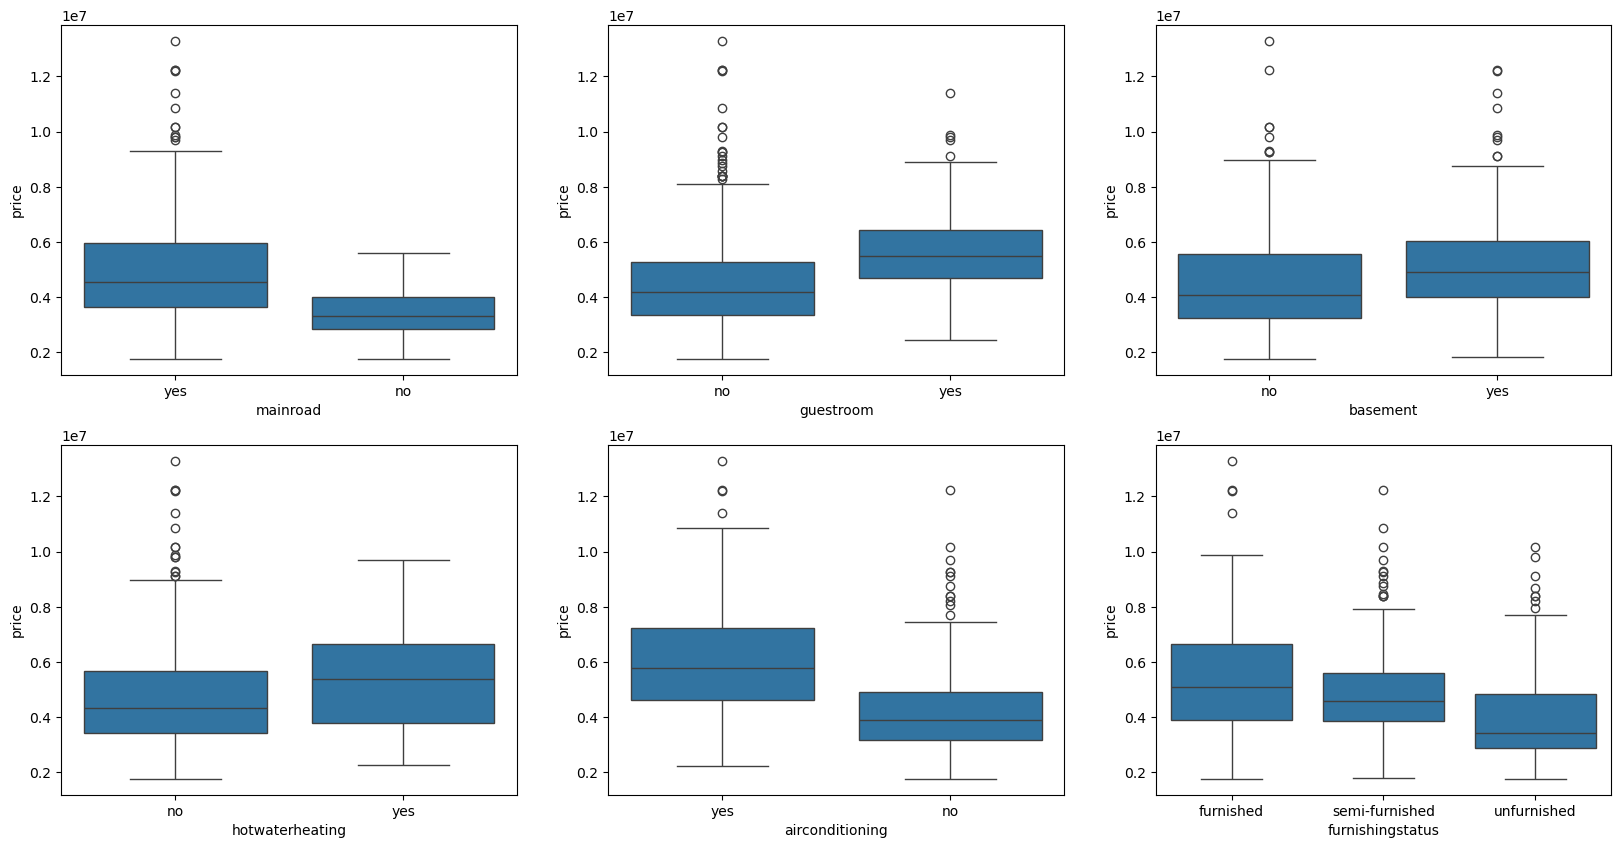

In [26]:
plt.figure(figsize=(20,10))

plt.subplot(2,3,1)
sns.boxplot(x='mainroad', y='price',data=housing)

plt.subplot(2,3,2)
sns.boxplot(x='guestroom', y='price',data=housing)

plt.subplot(2,3,3)
sns.boxplot(x='basement', y='price',data=housing)

plt.subplot(2,3,4)
sns.boxplot(x='hotwaterheating', y='price',data=housing)

plt.subplot(2,3,5)
sns.boxplot(x='airconditioning', y='price',data=housing)

plt.subplot(2,3,6)
sns.boxplot(x='furnishingstatus', y='price',data=housing)

In [28]:
#Data Preprocessing

In [30]:
#Action column with a Yes or No value

In [32]:
housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [36]:
varlist = ['mainroad','guestroom','basement','hotwaterheating','airconditioning','prefarea']

In [38]:
housing[varlist].head()

,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea
0,yes,no,no,no,yes,yes
1,yes,no,no,no,yes,no
2,yes,no,yes,no,no,yes
3,yes,no,yes,no,yes,yes
4,yes,yes,yes,no,yes,no


In [40]:
# Convert yes/no columns to 1/0
housing[varlist] = housing[varlist].apply(lambda col: col.map({'yes': 1, 'no': 0}))
housing[varlist].head()

,mainroad,guestroom,basement,hotwaterheating,airconditioning,prefarea
0,1,0,0,0,1,1
1,1,0,0,0,1,0
2,1,0,1,0,0,1
3,1,0,1,0,1,1
4,1,1,1,0,1,0


In [44]:
housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,furnished
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,furnished
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,semi-furnished
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,furnished
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,furnished


In [46]:
# Can we do something similar to the furnishing columns? Dummy Variable or dUMMY Encoding

When we apply the concept of dummy variable - 3 categories and we get 3-1 columns
- If we applying dummy variale to a columns with n distinct values - we get N-1 columns

In [55]:
status = pd.get_dummies(housing['furnishingstatus'],dtype = int)

In [69]:
status[(status['furnished'] == 1) | (status['semi-furnished'] == 1)]

,furnished,semi-furnished,unfurnished
0,1,0,0
1,1,0,0
2,0,1,0
3,1,0,0
4,1,0,0
...,...,...,...
522,1,0,0
523,1,0,0
527,0,1,0
541,0,1,0


In [71]:
status = pd.get_dummies(housing['furnishingstatus'],dtype = int,drop_first=True)

In [73]:
status

,semi-furnished,unfurnished
0,0,0
1,0,0
2,1,0
3,0,0
4,0,0
...,...,...
540,0,1
541,1,0
542,0,1
543,0,0


In [75]:
housing = pd.concat([housing,status],axis=1)

In [77]:
housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus,semi-furnished,unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,furnished,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,furnished,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,semi-furnished,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,furnished,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,furnished,0,0


In [79]:
housing.drop(['furnishingstatus'],axis = 1, inplace=True)

In [83]:
housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,semi-furnished,unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0,0


# Before we perform feature scaling, we need to split the data into test and train
-- Next, we perform feature scaling
--Also, why do we need to first split the data into train and test before we perform feature scaling

In [92]:
df_train,df_test = train_test_split(housing,train_size=0.7,test_size=0.3,random_state=100)

In [94]:
print(housing.shape)

(545, 14)


In [96]:
print(df_train.shape)

(381, 14)


In [98]:
print(df_test.shape)

(164, 14)


In [ ]:
# Rescale the feature

we performed 2 preprocessing steps
1. transalate 1 and 0 to a yes or no
2. apply dummy variable

# Data Standardization (Rescaling feature variable)
- Min Max Scaling or normalization = x-xmin /xmax-xmin
- Standardization = (x - mu) / Sigma

In [100]:
scaler

MinMaxScaler()

In [102]:
housing.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,semi-furnished,unfurnished
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1,0
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0,0


In [ ]:
# we are scaling numeric varaible like, Price, bedroom,bathroom,stories and parking

In [104]:
num_vars = ['price','area','bedrooms','bathrooms','stories','parking']

In [108]:
df_train[num_vars].head()

,price,area,bedrooms,bathrooms,stories,parking
359,3710000,3600,3,1,1,1
19,8855000,6420,3,2,2,1
159,5460000,3150,3,2,1,0
35,8080940,7000,3,2,4,2
28,8400000,7950,5,2,2,2


In [112]:
df_train[num_vars] = scaler.fit_transform(df_train[num_vars])

In [114]:
df_train[num_vars].head()

,price,area,bedrooms,bathrooms,stories,parking
359,0.169697,0.155227,0.4,0.0,0.000000,0.333333
19,0.615152,0.403379,0.4,0.5,0.333333,0.333333
159,0.321212,0.115628,0.4,0.5,0.000000,0.000000
35,0.548133,0.454417,0.4,0.5,1.000000,0.666667
28,0.575758,0.538015,0.8,0.5,0.333333,0.666667


In [116]:
# normalization = x-min/xmax - xmin

In [123]:
df_train[num_vars].describe()

,price,area,bedrooms,bathrooms,stories,parking
count,381.000000,381.000000,381.000000,381.000000,381.000000,381.000000
mean,0.260333,0.288710,0.386352,0.136483,0.268591,0.242345
std,0.157607,0.181420,0.147336,0.237325,0.295001,0.285933
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.151515,0.155227,0.200000,0.000000,0.000000,0.000000
50%,0.221212,0.234424,0.400000,0.000000,0.333333,0.000000
75%,0.345455,0.398099,0.400000,0.500000,0.333333,0.333333
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
#Building model

#There are 2 ways of building out multiple LINER REGRESSION MODEL

1. We start with just 1 variable - akin to a simple linear model - and then we iteratively add new variable to it -- Bottom up approach
2. User all the varaible in one go and iteratively remove one variable after another -- Top Down Approach

In [ ]:
## Bottom up Approach

<Axes: >

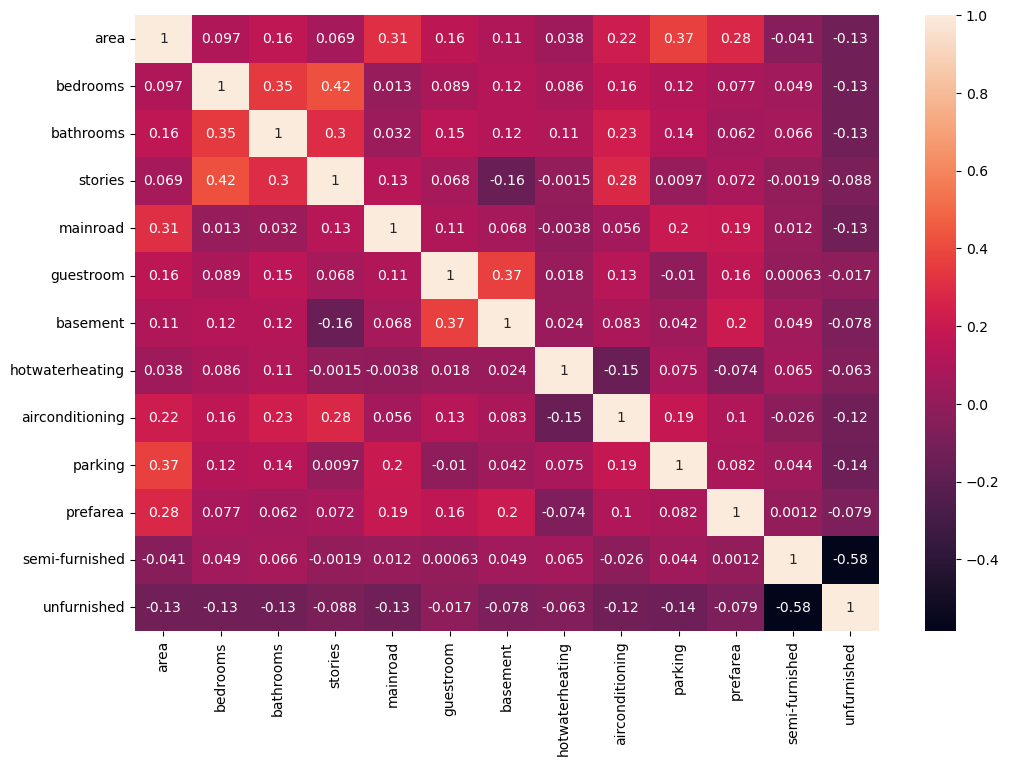

In [146]:
plt.figure(figsize=(12, 8))
sns.heatmap(df_train.corr(),annot=True)

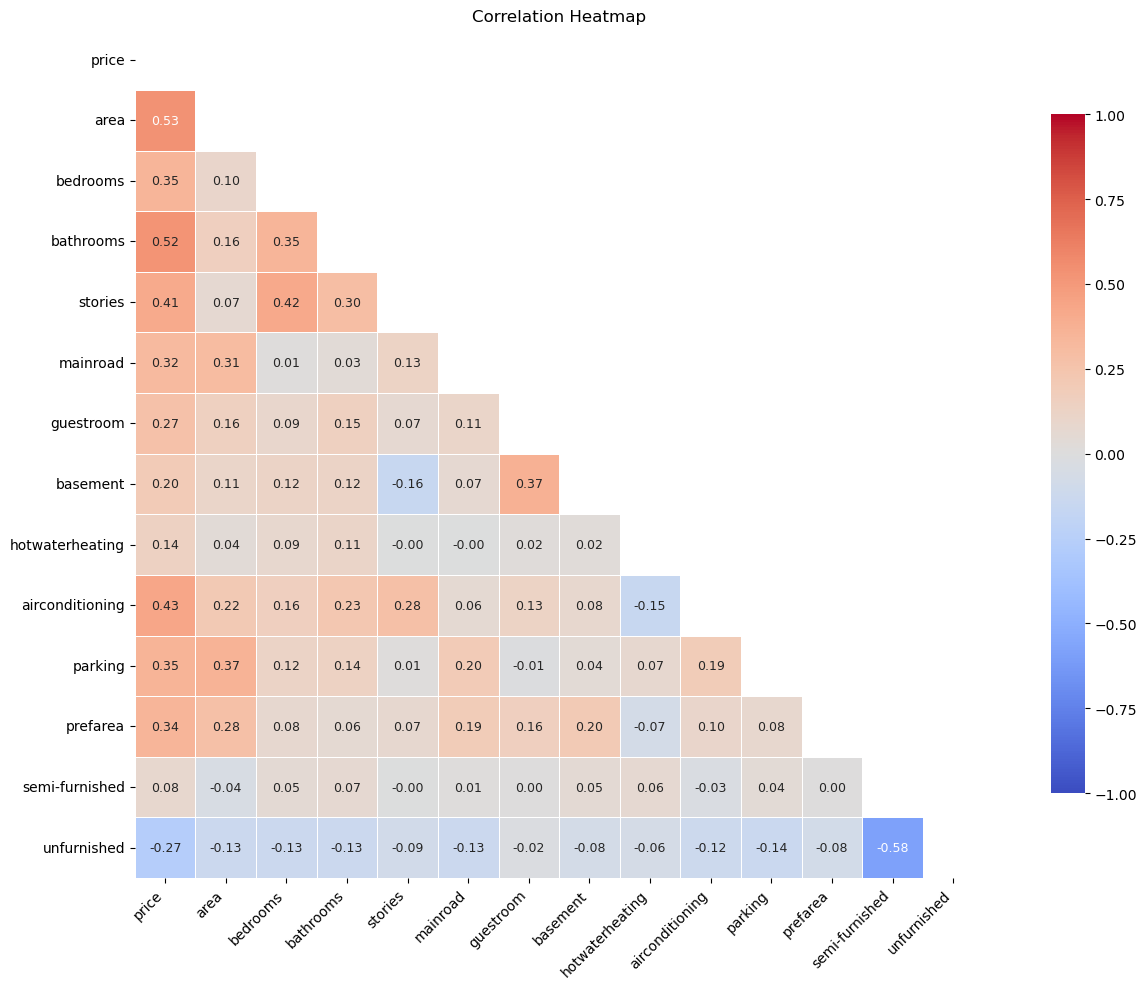

In [136]:
import numpy as np
import matplotlib.pyplot as plt

corr = df_train.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))   # hide the duplicate upper half

plt.figure(figsize=(14, 10))                      # bigger canvas
sns.heatmap(corr,
            mask=mask,
            annot=True, fmt=".2f",                # 2 decimals instead of long floats
            annot_kws={"size": 9},
            cmap="coolwarm", center=0,            # red = positive, blue = negative
            vmin=-1, vmax=1,
            linewidths=0.5, square=True,
            cbar_kws={"shrink": 0.8})
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

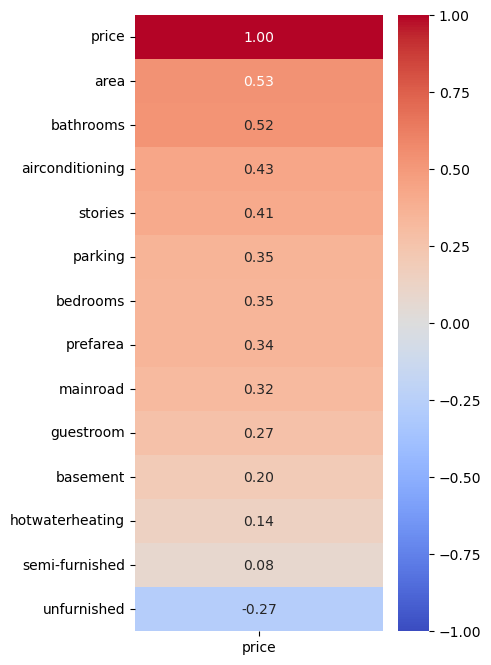

In [138]:
plt.figure(figsize=(4, 8))
sns.heatmap(corr[['price']].sort_values('price', ascending=False),
            annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.show()

In [140]:
#Separate the X and y variable for training

y_train = df_train.pop('price')
X_train = df_train

In [150]:
## fit the model 
import statsmodels.api as sm

In [152]:
#Fit the constant

X_train_sm = sm.add_constant(X_train['area'])

X_train_sm.head()

,const,area
359,1.0,0.155227
19,1.0,0.403379
159,1.0,0.115628
35,1.0,0.454417
28,1.0,0.538015


In [168]:
y_train.head()

359    0.169697
19     0.615152
159    0.321212
35     0.548133
28     0.575758
Name: price, dtype: float64

In [154]:
lr = sm.OLS(y_train,X_train_sm)

In [156]:
lr_model = lr.fit()

In [158]:
lr_model.params

const    0.126894
area     0.462192
dtype: float64

In [164]:
lr_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.283
Model:                            OLS   Adj. R-squared:                  0.281
Method:                 Least Squares   F-statistic:                     149.6
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           3.15e-29
Time:                        20:56:35   Log-Likelihood:                 227.23
No. Observations:                 381   AIC:                            -450.5
Df Residuals:                     379   BIC:                            -442.6
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1269      0.013      9.853      0.000       0.102       0.152
area           0.4622      0.038     12.232      0.000       0.388       0.536
==============================================================================
Omnibus:                       67.313   Durbin-Watson:                   2.018
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              143.063
Skew:                           0.925   Prob(JB):                     8.59e-32
Kurtosis:                       5.365   Cond. No.                         5.99
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

------ we have low r square and 28% is not a good representation, we need to add another variable, which is "Bathroom"

In [186]:
X_train_sm = X_train[['area','bathrooms']]

In [188]:
X_train_sm = sm.add_constant(X_train_sm)

In [190]:
X_train_sm

,const,area,bathrooms
359,1.0,0.155227,0.0
19,1.0,0.403379,0.5
159,1.0,0.115628,0.5
35,1.0,0.454417,0.5
28,1.0,0.538015,0.5
...,...,...,...
526,1.0,0.118268,0.0
53,1.0,0.291623,0.5
350,1.0,0.139388,0.0
79,1.0,0.366420,0.5


In [192]:
lr = sm.OLS(y_train,X_train_sm)

In [194]:
lr_model = lr.fit()

In [196]:
lr_model.params

const        0.104589
area         0.398396
bathrooms    0.298374
dtype: float64

In [198]:
lr_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.480
Model:                            OLS   Adj. R-squared:                  0.477
Method:                 Least Squares   F-statistic:                     174.1
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           2.51e-54
Time:                        21:13:24   Log-Likelihood:                 288.24
No. Observations:                 381   AIC:                            -570.5
Df Residuals:                     378   BIC:                            -558.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1046      0.011      9.384      0.000       0.083       0.127
area           0.3984      0.033     12.192      0.000       0.334       0.463
bathrooms      0.2984      0.025     11.945      0.000       0.249       0.347
==============================================================================
Omnibus:                       62.839   Durbin-Watson:                   2.157
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              168.790
Skew:                           0.784   Prob(JB):                     2.23e-37
Kurtosis:                       5.859   Cond. No.                         6.17
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [200]:
# Explainatory of the model is still no so good, we go ahaed and add another variable to the model to improve

In [202]:
X_train_sm = X_train[['area','bathrooms','bedrooms']]

In [204]:
X_train_sm = sm.add_constant(X_train_sm)

In [206]:
lr = sm.OLS(y_train,X_train_sm)

In [208]:
lr_model = lr.fit()

In [210]:
lr_model.params

const        0.041352
area         0.392211
bathrooms    0.259978
bedrooms     0.181863
dtype: float64

In [212]:
lr_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.505
Model:                            OLS   Adj. R-squared:                  0.501
Method:                 Least Squares   F-statistic:                     128.2
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           3.12e-57
Time:                        21:17:29   Log-Likelihood:                 297.76
No. Observations:                 381   AIC:                            -587.5
Df Residuals:                     377   BIC:                            -571.7
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0414      0.018      2.292      0.022       0.006       0.077
area           0.3922      0.032     12.279      0.000       0.329       0.455
bathrooms      0.2600      0.026     10.033      0.000       0.209       0.311
bedrooms       0.1819      0.041      4.396      0.000       0.101       0.263
==============================================================================
Omnibus:                       50.037   Durbin-Watson:                   2.136
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              124.806
Skew:                           0.648   Prob(JB):                     7.92e-28
Kurtosis:                       5.487   Cond. No.                         8.87
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [216]:
X_train_sm = X_train[['area','bathrooms','bedrooms','airconditioning']]

In [218]:
X_train_sm = sm.add_constant(X_train_sm)

In [220]:
lr = sm.OLS(y_train,X_train_sm)

In [222]:
lr_model = lr.fit()

In [224]:
lr_model.params

const              0.039668
area               0.354583
bathrooms          0.232922
bedrooms           0.159799
airconditioning    0.082766
dtype: float64

In [226]:
lr_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.558
Model:                            OLS   Adj. R-squared:                  0.553
Method:                 Least Squares   F-statistic:                     118.5
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           2.77e-65
Time:                        21:19:02   Log-Likelihood:                 319.19
No. Observations:                 381   AIC:                            -628.4
Df Residuals:                     376   BIC:                            -608.7
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.0397      0.017      2.323      0.021       0.006       0.073
area                0.3546      0.031     11.530      0.000       0.294       0.415
bathrooms           0.2329      0.025      9.370      0.000       0.184       0.282
bedrooms            0.1598      0.039      4.066      0.000       0.083       0.237
airconditioning     0.0828      0.012      6.691      0.000       0.058       0.107
==============================================================================
Omnibus:                       57.748   Durbin-Watson:                   2.094
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              137.632
Skew:                           0.761   Prob(JB):                     1.30e-30
Kurtosis:                       5.520   Cond. No.                         9.27
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [ ]:
# Top down Approach

In [228]:
housing.columns

Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'semi-furnished', 'unfurnished'],
      dtype='object')

In [230]:
X_train_sm = sm.add_constant(X_train)

In [232]:
X_train_sm.head()

,const,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,semi-furnished,unfurnished
359,1.0,0.155227,0.4,0.0,0.000000,1,0,0,0,0,0.333333,0,0,1
19,1.0,0.403379,0.4,0.5,0.333333,1,0,0,0,1,0.333333,1,1,0
159,1.0,0.115628,0.4,0.5,0.000000,1,1,1,0,1,0.000000,0,0,0
35,1.0,0.454417,0.4,0.5,1.000000,1,0,0,0,1,0.666667,0,0,0
28,1.0,0.538015,0.8,0.5,0.333333,1,0,1,1,0,0.666667,0,0,1


In [234]:
lr = sm.OLS(y_train,X_train_sm)

In [236]:
lr_model = lr.fit()

In [238]:
lr_model.params

const              0.020033
area               0.234664
bedrooms           0.046735
bathrooms          0.190823
stories            0.108516
mainroad           0.050441
guestroom          0.030428
basement           0.021595
hotwaterheating    0.084863
airconditioning    0.066881
parking            0.060735
prefarea           0.059428
semi-furnished     0.000921
unfurnished       -0.031006
dtype: float64

In [240]:
lr_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.681
Model:                            OLS   Adj. R-squared:                  0.670
Method:                 Least Squares   F-statistic:                     60.40
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           8.83e-83
Time:                        21:29:38   Log-Likelihood:                 381.79
No. Observations:                 381   AIC:                            -735.6
Df Residuals:                     367   BIC:                            -680.4
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.0200      0.021      0.955      0.340      -0.021       0.061
area                0.2347      0.030      7.795      0.000       0.175       0.294
bedrooms            0.0467      0.037      1.267      0.206      -0.026       0.119
bathrooms           0.1908      0.022      8.679      0.000       0.148       0.234
stories             0.1085      0.019      5.661      0.000       0.071       0.146
mainroad            0.0504      0.014      3.520      0.000       0.022       0.079
guestroom           0.0304      0.014      2.233      0.026       0.004       0.057
basement            0.0216      0.011      1.943      0.053      -0.000       0.043
hotwaterheating     0.0849      0.022      3.934      0.000       0.042       0.127
airconditioning     0.0669      0.011      5.899      0.000       0.045       0.089
parking             0.0607      0.018      3.365      0.001       0.025       0.096
prefarea            0.0594      0.012      5.040      0.000       0.036       0.083
semi-furnished      0.0009      0.012      0.078      0.938      -0.022       0.024
unfurnished        -0.0310      0.013     -2.440      0.015      -0.056      -0.006
==============================================================================
Omnibus:                       93.687   Durbin-Watson:                   2.093
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              304.917
Skew:                           1.091   Prob(JB):                     6.14e-67
Kurtosis:                       6.801   Cond. No.                         14.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

# Drop variable recursively
1. variable with a high VIF
2. Insignificant variable - High P-value

In [253]:
## How to find out variance inflation Factor VIF

from statsmodels.stats.outliers_influence import variance_inflation_factor

In [255]:
vif = pd.DataFrame()

vif['Features'] = X_train.columns

In [257]:
vif['VIF'] = [variance_inflation_factor(X_train.values,i) for i in range(X_train.shape[1])]

In [259]:
vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by='VIF', ascending=False)
vif

,Features,VIF
1,bedrooms,7.33
4,mainroad,6.02
0,area,4.67
3,stories,2.70
11,semi-furnished,2.19
9,parking,2.12
6,basement,2.02
12,unfurnished,1.82
8,airconditioning,1.77
2,bathrooms,1.67


# VIF is regression model which gives a score and that score represent Multicollinearity, and we have to get rid of those columns
# A number below 5 we can consider, above 5 we can't. 
# VIF is also not one condition, we also want to include p-value
# High P value and low VIF -- 1st we go ahaed and remove it -- build the model--  OR hIGH VIF and low P-value 

In [ ]:
# we are removing value having HIGH P-VALUE 'Semi- furnished'

In [271]:
X_train = X_train.drop('semi-furnished',axis = 1)

In [273]:
X_train

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,unfurnished
359,0.155227,0.4,0.0,0.000000,1,0,0,0,0,0.333333,0,1
19,0.403379,0.4,0.5,0.333333,1,0,0,0,1,0.333333,1,0
159,0.115628,0.4,0.5,0.000000,1,1,1,0,1,0.000000,0,0
35,0.454417,0.4,0.5,1.000000,1,0,0,0,1,0.666667,0,0
28,0.538015,0.8,0.5,0.333333,1,0,1,1,0,0.666667,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
526,0.118268,0.2,0.0,0.000000,1,0,0,0,0,0.000000,0,1
53,0.291623,0.4,0.5,1.000000,1,0,0,0,1,0.666667,0,0
350,0.139388,0.2,0.0,0.333333,1,0,0,1,0,0.333333,0,0
79,0.366420,0.4,0.5,0.666667,1,1,0,0,1,0.000000,0,0


In [275]:
X_train_sm = sm.add_constant(X_train)

In [279]:
X_train_sm.head()

,const,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,unfurnished
359,1.0,0.155227,0.4,0.0,0.000000,1,0,0,0,0,0.333333,0,1
19,1.0,0.403379,0.4,0.5,0.333333,1,0,0,0,1,0.333333,1,0
159,1.0,0.115628,0.4,0.5,0.000000,1,1,1,0,1,0.000000,0,0
35,1.0,0.454417,0.4,0.5,1.000000,1,0,0,0,1,0.666667,0,0
28,1.0,0.538015,0.8,0.5,0.333333,1,0,1,1,0,0.666667,0,1


In [281]:
lr = sm.OLS(y_train,X_train_sm)

In [283]:
lr_model = lr.fit()

In [285]:
lr_model.params

const              0.020740
area               0.234404
bedrooms           0.046710
bathrooms          0.190876
stories            0.108475
mainroad           0.050401
guestroom          0.030447
basement           0.021605
hotwaterheating    0.084890
airconditioning    0.066803
parking            0.060761
prefarea           0.059419
unfurnished       -0.031594
dtype: float64

In [289]:
lr_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.681
Model:                            OLS   Adj. R-squared:                  0.671
Method:                 Least Squares   F-statistic:                     65.61
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           1.07e-83
Time:                        21:46:57   Log-Likelihood:                 381.79
No. Observations:                 381   AIC:                            -737.6
Df Residuals:                     368   BIC:                            -686.3
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.0207      0.019      1.098      0.273      -0.016       0.058
area                0.2344      0.030      7.845      0.000       0.176       0.293
bedrooms            0.0467      0.037      1.268      0.206      -0.026       0.119
bathrooms           0.1909      0.022      8.697      0.000       0.148       0.234
stories             0.1085      0.019      5.669      0.000       0.071       0.146
mainroad            0.0504      0.014      3.524      0.000       0.022       0.079
guestroom           0.0304      0.014      2.238      0.026       0.004       0.057
basement            0.0216      0.011      1.946      0.052      -0.000       0.043
hotwaterheating     0.0849      0.022      3.941      0.000       0.043       0.127
airconditioning     0.0668      0.011      5.923      0.000       0.045       0.089
parking             0.0608      0.018      3.372      0.001       0.025       0.096
prefarea            0.0594      0.012      5.046      0.000       0.036       0.083
unfurnished        -0.0316      0.010     -3.096      0.002      -0.052      -0.012
==============================================================================
Omnibus:                       93.538   Durbin-Watson:                   2.092
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              303.844
Skew:                           1.090   Prob(JB):                     1.05e-66
Kurtosis:                       6.794   Cond. No.                         14.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [291]:
vif = pd.DataFrame()

vif['Features'] = X_train.columns

vif['VIF'] = [variance_inflation_factor(X_train.values,i) for i in range(X_train.shape[1])]

vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by='VIF', ascending=False)
vif

,Features,VIF
1,bedrooms,6.59
4,mainroad,5.68
0,area,4.67
3,stories,2.69
9,parking,2.12
6,basement,2.01
8,airconditioning,1.77
2,bathrooms,1.67
10,prefarea,1.51
5,guestroom,1.47


In [293]:
# VIF is also reduced for bedrooms and mainroad, after removing semi-furnished, Model is much better now

In [295]:
#Let's remove BedRooms now

In [299]:
X_train = X_train.drop('bedrooms',axis = 1)

X_train.head()

,area,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,unfurnished
359,0.155227,0.0,0.000000,1,0,0,0,0,0.333333,0,1
19,0.403379,0.5,0.333333,1,0,0,0,1,0.333333,1,0
159,0.115628,0.5,0.000000,1,1,1,0,1,0.000000,0,0
35,0.454417,0.5,1.000000,1,0,0,0,1,0.666667,0,0
28,0.538015,0.5,0.333333,1,0,1,1,0,0.666667,0,1


In [301]:
X_train_sm = sm.add_constant(X_train)

In [303]:
lr = sm.OLS(y_train,X_train_sm)

In [305]:
lr_model = lr.fit()

In [307]:
lr_model.params

const              0.035722
area               0.234746
bathrooms          0.196480
stories            0.117751
mainroad           0.048798
guestroom          0.030097
basement           0.023917
hotwaterheating    0.086403
airconditioning    0.066533
parking            0.062872
prefarea           0.059643
unfurnished       -0.032317
dtype: float64

In [309]:
lr_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.680
Model:                            OLS   Adj. R-squared:                  0.671
Method:                 Least Squares   F-statistic:                     71.31
Date:                Sun, 15 Nov 2026   Prob (F-statistic):           2.73e-84
Time:                        21:51:35   Log-Likelihood:                 380.96
No. Observations:                 381   AIC:                            -737.9
Df Residuals:                     369   BIC:                            -690.6
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
===================================================================================
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.0357      0.015      2.421      0.016       0.007       0.065
area                0.2347      0.030      7.851      0.000       0.176       0.294
bathrooms           0.1965      0.022      9.132      0.000       0.154       0.239
stories             0.1178      0.018      6.654      0.000       0.083       0.153
mainroad            0.0488      0.014      3.423      0.001       0.021       0.077
guestroom           0.0301      0.014      2.211      0.028       0.003       0.057
basement            0.0239      0.011      2.183      0.030       0.002       0.045
hotwaterheating     0.0864      0.022      4.014      0.000       0.044       0.129
airconditioning     0.0665      0.011      5.895      0.000       0.044       0.089
parking             0.0629      0.018      3.501      0.001       0.028       0.098
prefarea            0.0596      0.012      5.061      0.000       0.036       0.083
unfurnished        -0.0323      0.010     -3.169      0.002      -0.052      -0.012
==============================================================================
Omnibus:                       97.661   Durbin-Watson:                   2.097
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              325.388
Skew:                           1.130   Prob(JB):                     2.20e-71
Kurtosis:                       6.923   Cond. No.                         10.6
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [311]:
vif = pd.DataFrame()

vif['Features'] = X_train.columns

vif['VIF'] = [variance_inflation_factor(X_train.values,i) for i in range(X_train.shape[1])]

vif['VIF'] = round(vif['VIF'], 2)
vif = vif.sort_values(by='VIF', ascending=False)
vif

,Features,VIF
3,mainroad,4.79
0,area,4.55
2,stories,2.23
8,parking,2.10
5,basement,1.87
7,airconditioning,1.76
1,bathrooms,1.61
9,prefarea,1.50
4,guestroom,1.46
10,unfurnished,1.33


In [313]:
# Now, the VIF for the mainroad is also reduced and all the P-value for the columns is also significant

# Residual Analysis 

In [320]:
y_train_pred = lr_model.predict(X_train_sm)

In [322]:
res = y_train  - y_train_pred

/var/folders/d9/zn0fzv5j3wv4ldx8c1wgtq9h0000gn/T/ipykernel_13255/2154591961.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(res)


<Axes: ylabel='Density'>

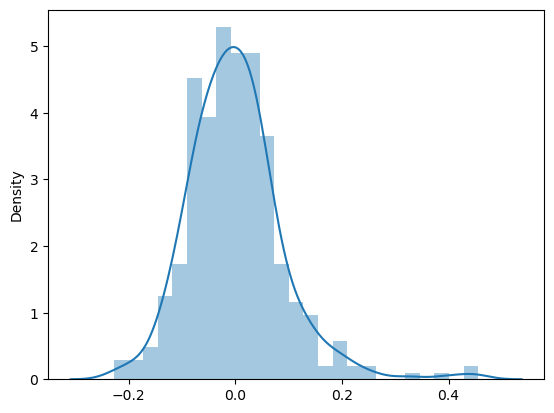

In [324]:
sns.distplot(res)

# Model is good:
1. Decent R square
2. It does not have any variable with High VIF or a Significant P value

In [ ]:
# we need to apply to the test dataset

# we need to transform the dataset

# need to apply the